In [3]:
%pip install mysql-connector-python pandas matplotlib seaborn


Note: you may need to restart the kernel to use updated packages.


In [1]:
import mysql.connector
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="darkgrid", context="notebook")

connection = mysql.connector.connect(
    host="localhost",
    user="root",
    password="root",
    database="HotelBookingDB"
)

cursor = connection.cursor()
print("Database connected successfully:", connection.is_connected())


Database connected successfully: True


## 3. Load the three tables
This cell checks the real column names in your database and loads the tables into pandas DataFrames.

In [2]:
table_names = ["Guests", "Rooms", "Bookings"]
dataframes = {}

for table_name in table_names:
    cursor.execute(f"SHOW TABLES LIKE '{table_name}'")
    if cursor.fetchone() is None:
        raise ValueError(
            f"Table '{table_name}' was not found in HotelBookingDB. "
            "Check the exact table name in MySQL Workbench."
        )
    dataframes[table_name] = pd.read_sql(f"SELECT * FROM `{table_name}`", connection)

guests_df = dataframes["Guests"]
rooms_df = dataframes["Rooms"]
bookings_df = dataframes["Bookings"]

print("Guests:", guests_df.shape)
print("Rooms:", rooms_df.shape)
print("Bookings:", bookings_df.shape)

print("\nGuests columns:", guests_df.columns.tolist())
print("Rooms columns:", rooms_df.columns.tolist())
print("Bookings columns:", bookings_df.columns.tolist())

display(bookings_df.head())


Guests: (100, 5)
Rooms: (100, 4)
Bookings: (100, 6)

Guests columns: ['Guest_ID', 'Guest_Name', 'City', 'Phone', 'Email']
Rooms columns: ['Room_ID', 'Room_Type', 'Price_Per_Night', 'Room_Status']
Bookings columns: ['Booking_ID', 'Guest_ID', 'Room_ID', 'Check_In', 'Check_Out', 'Booking_Status']


,Booking_ID,Guest_ID,Room_ID,Check_In,Check_Out,Booking_Status
0,1,7,13,2026-01-05,2026-01-07,Cancelled
1,2,14,26,2026-01-09,2026-01-12,Checked-Out
2,3,21,39,2026-01-13,2026-01-17,Checked-In
3,4,28,52,2026-01-17,2026-01-22,Confirmed
4,5,35,65,2026-01-21,2026-01-22,Cancelled


## 4. Prepare flexible chart data
The helper functions below detect likely date, numeric, category, guest, room, and booking-status columns from your actual schema. If a column has a different name, the notebook will still use available data where possible.

In [3]:
def find_col(df, keywords):
    # First look for exact/partial keyword matches in column names.
    cols = list(df.columns)
    lowered = {c: str(c).lower().replace(" ", "_") for c in cols}
    for key in keywords:
        for col in cols:
            if key in lowered[col]:
                return col
    return None

def numeric_columns(df):
    return list(df.select_dtypes(include=np.number).columns)

def categorical_columns(df):
    return [
        c for c in df.columns
        if (df[c].dtype == "object" or str(df[c].dtype) == "category" or df[c].nunique(dropna=True) <= 15)
        and df[c].nunique(dropna=True) > 1
    ]

def get_date_series(df):
    date_col = find_col(df, ["booking_date", "check_in", "checkin", "arrival_date", "date", "created_at", "check_out", "checkout"])
    if date_col:
        parsed = pd.to_datetime(df[date_col], errors="coerce")
        if parsed.notna().sum() > 0:
            return parsed, date_col
    return pd.Series(pd.date_range("2026-01-01", periods=len(df), freq="D"), index=df.index), None

def get_numeric_series(df):
    nums = numeric_columns(df)
    if nums:
        col = find_col(df, ["total_amount", "total_price", "booking_amount", "revenue", "price", "amount", "salary", "cost", "rate", "room_price"])
        if col not in nums:
            col = nums[0]
        return pd.to_numeric(df[col], errors="coerce"), col
    return pd.Series(np.arange(1, len(df) + 1), index=df.index, dtype=float), None

def get_category_series(df):
    cats = categorical_columns(df)
    preferred = find_col(df, ["booking_status", "status", "room_type", "room_status", "payment_status", "city", "location", "gender", "category"])
    if preferred in cats:
        col = preferred
    elif cats:
        col = cats[0]
    else:
        col = None
    if col:
        return df[col].fillna("Unknown").astype(str), col
    return pd.Series(["All Records"] * len(df), index=df.index), None

# Create clean chart-ready columns based on Bookings.
chart_df = bookings_df.copy()
chart_df["_chart_value"], value_col = get_numeric_series(chart_df)
chart_df["_chart_category"], category_col = get_category_series(chart_df)
chart_df["_chart_date"], date_col = get_date_series(chart_df)
chart_df = chart_df.reset_index(drop=True)

if chart_df.empty:
    raise ValueError("Bookings table is empty. Add booking rows in MySQL, then rerun this notebook.")

print("Numeric measure used:", value_col or "record count (no numeric column found)")
print("Category used:", category_col or "all records")
print("Date used:", date_col or "generated row sequence (no date column found)")


Numeric measure used: Booking_ID
Category used: Booking_Status
Date used: Check_In


# Part A — 10 Individual Charts
Each chart is created separately. Chart titles and labels are generated from the columns detected in your database.

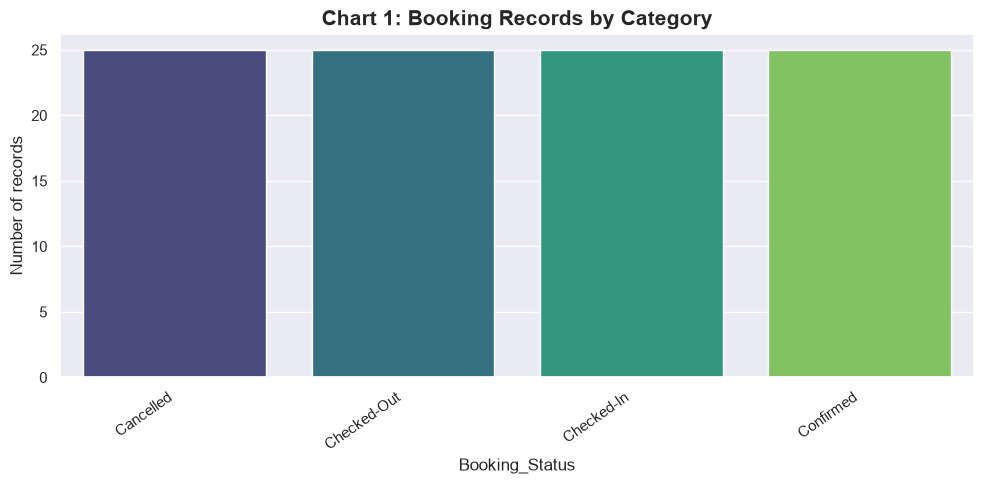

In [4]:
# Chart 1 — Count plot: number of records per category
plt.figure(figsize=(10, 5))
order = chart_df["_chart_category"].value_counts().index
sns.countplot(data=chart_df, x="_chart_category", order=order, hue="_chart_category", legend=False, palette="viridis")
plt.title("Chart 1: Booking Records by Category", fontsize=15, weight="bold")
plt.xlabel(category_col or "Category")
plt.ylabel("Number of records")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


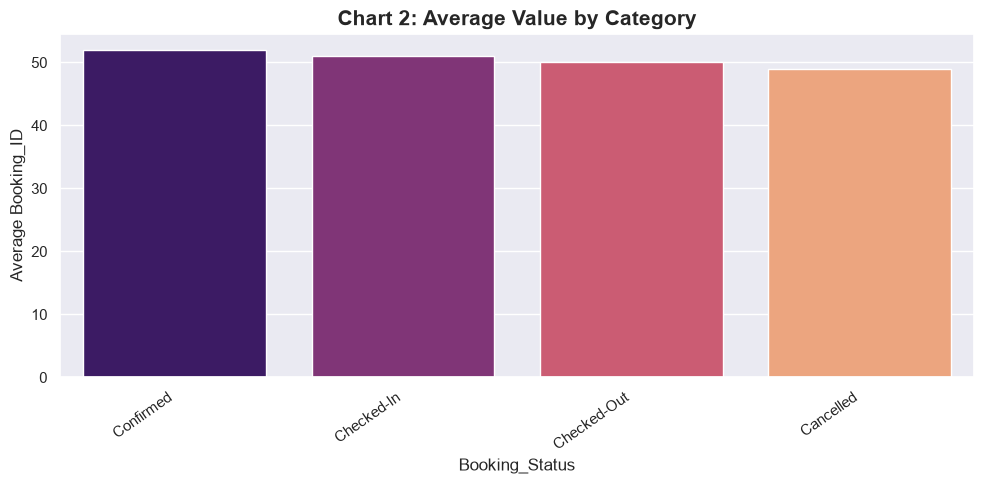

In [5]:
# Chart 2 — Bar chart: average numeric value by category
bar_data = chart_df.groupby("_chart_category", dropna=False)["_chart_value"].mean().sort_values(ascending=False).head(12).reset_index()
plt.figure(figsize=(10, 5))
sns.barplot(data=bar_data, x="_chart_category", y="_chart_value", hue="_chart_category", legend=False, palette="magma")
plt.title("Chart 2: Average Value by Category", fontsize=15, weight="bold")
plt.xlabel(category_col or "Category")
plt.ylabel(f"Average {value_col or 'record value'}")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


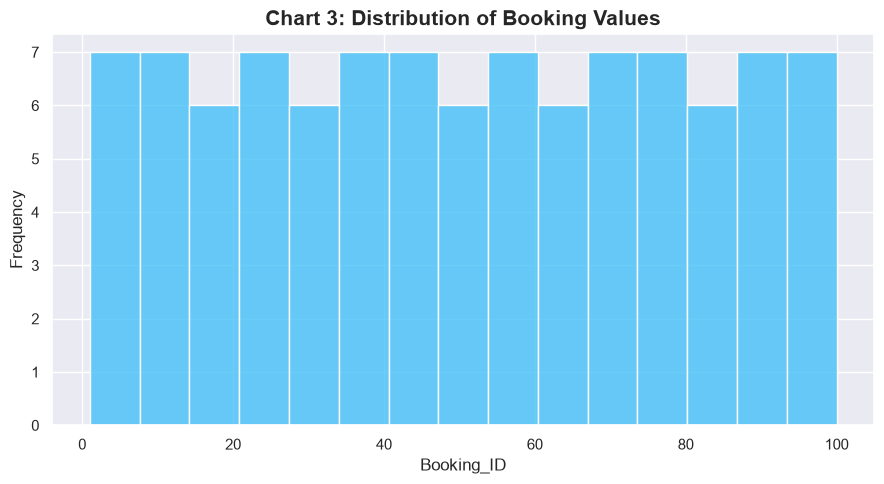

In [6]:
# Chart 3 — Histogram: distribution of the selected numeric measure
plt.figure(figsize=(9, 5))
sns.histplot(chart_df["_chart_value"].dropna(), bins=15, kde=False, color="#38bdf8", edgecolor="white")
plt.title("Chart 3: Distribution of Booking Values", fontsize=15, weight="bold")
plt.xlabel(value_col or "Record number")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


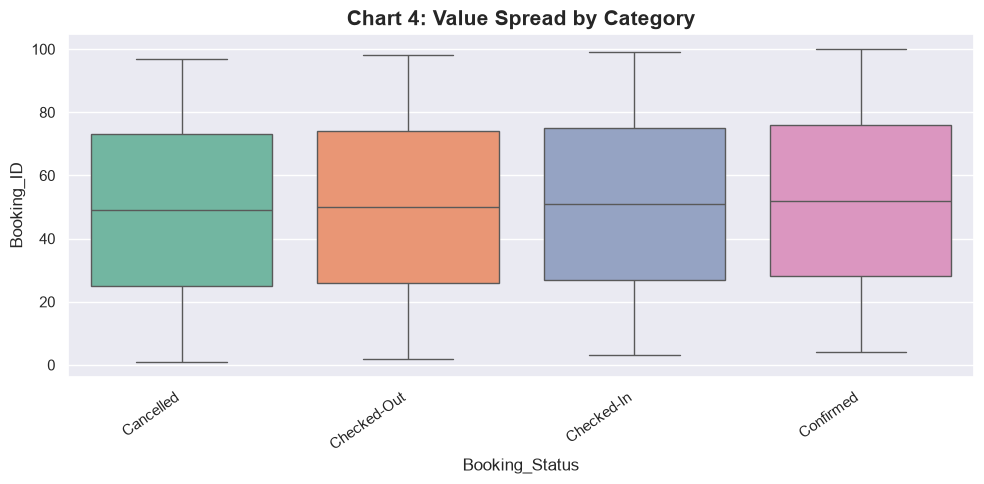

In [7]:
# Chart 4 — Box plot: numeric value across categories
plt.figure(figsize=(10, 5))
sns.boxplot(data=chart_df, x="_chart_category", y="_chart_value", hue="_chart_category", legend=False, palette="Set2")
plt.title("Chart 4: Value Spread by Category", fontsize=15, weight="bold")
plt.xlabel(category_col or "Category")
plt.ylabel(value_col or "Record value")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


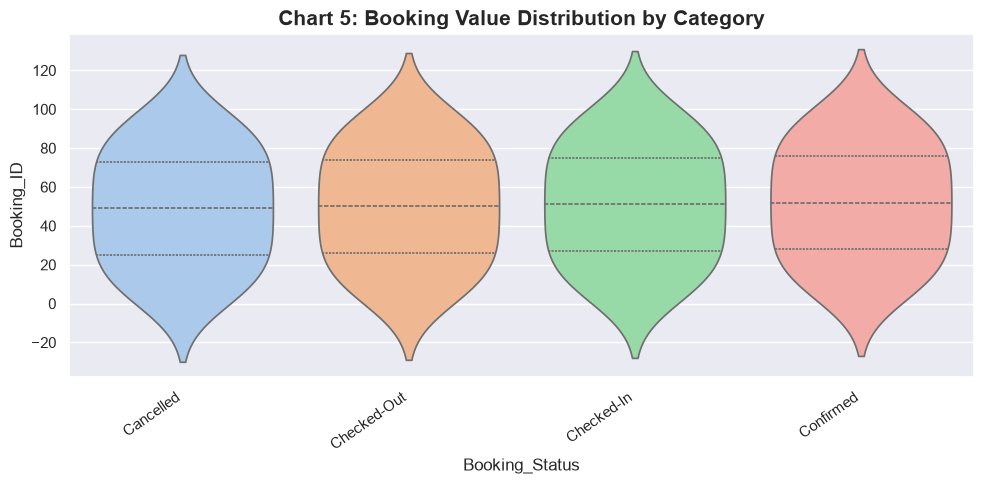

In [11]:
# Chart 5 — Violin plot
plt.figure(figsize=(10, 5))
sns.violinplot(data=chart_df, x="_chart_category", y="_chart_value", hue="_chart_category", legend=False, inner="quartile", palette="pastel")
plt.title("Chart 5: Booking Value Distribution by Category", fontsize=15, weight="bold")
plt.xlabel(category_col or "Category")
plt.ylabel(value_col or "Record value")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


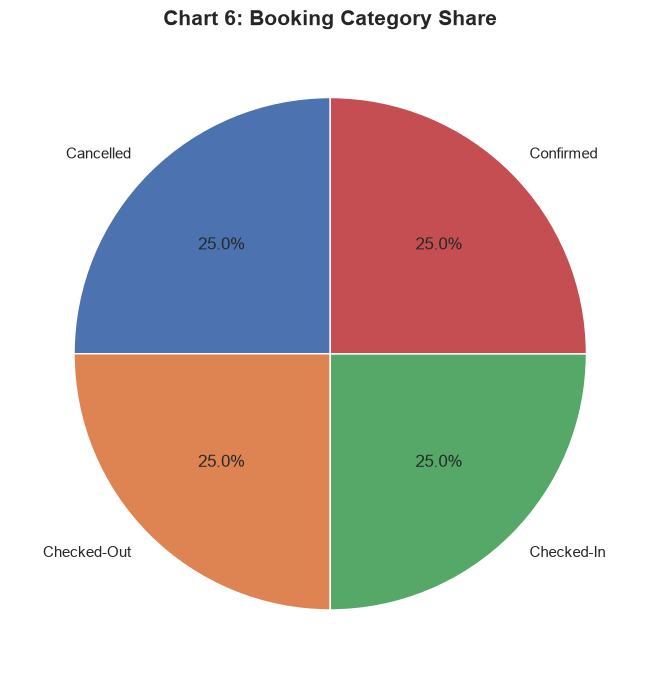

In [12]:
# Chart 6 — Pie chart: category share
pie_data = chart_df["_chart_category"].value_counts().head(8)
plt.figure(figsize=(7, 7))
plt.pie(pie_data.values, labels=pie_data.index, autopct="%1.1f%%", startangle=90, wedgeprops={"edgecolor": "white"})
plt.title("Chart 6: Booking Category Share", fontsize=15, weight="bold")
plt.tight_layout()
plt.show()


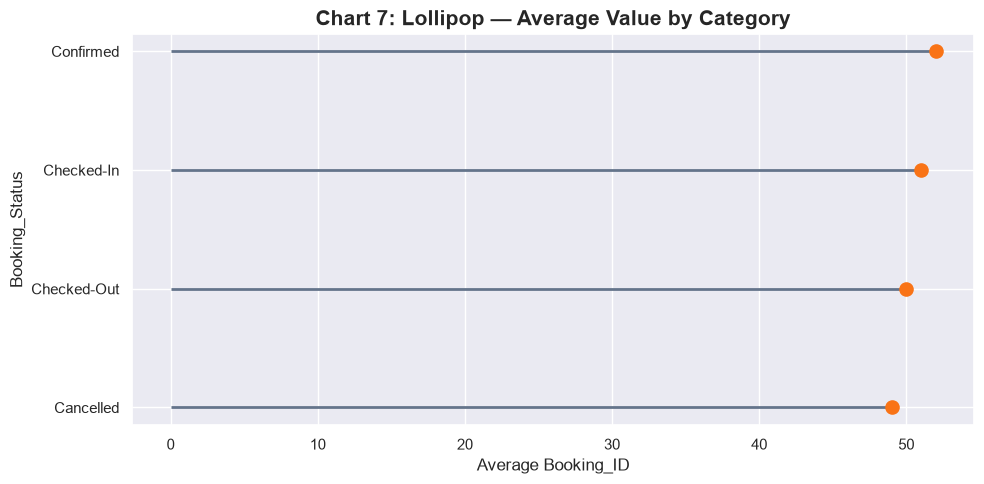

In [13]:
# Chart 7 — Lollipop chart: average value by category
lollipop = chart_df.groupby("_chart_category")["_chart_value"].mean().sort_values().tail(12)
plt.figure(figsize=(10, 5))
plt.hlines(y=lollipop.index, xmin=0, xmax=lollipop.values, linewidth=2, color="#64748b")
plt.scatter(lollipop.values, lollipop.index, s=90, color="#f97316", zorder=3)
plt.title("Chart 7: Lollipop — Average Value by Category", fontsize=15, weight="bold")
plt.xlabel(f"Average {value_col or 'record value'}")
plt.ylabel(category_col or "Category")
plt.tight_layout()
plt.show()


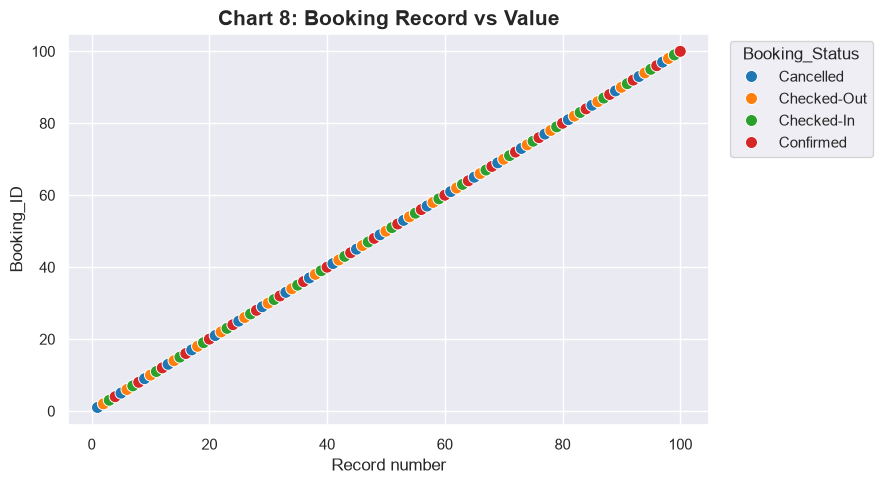

In [14]:
# Chart 8 — Scatter plot: record sequence versus numeric value
scatter_df = chart_df.copy()
scatter_df["_record_number"] = np.arange(1, len(scatter_df) + 1)
plt.figure(figsize=(9, 5))
sns.scatterplot(data=scatter_df, x="_record_number", y="_chart_value", hue="_chart_category", palette="tab10", s=75)
plt.title("Chart 8: Booking Record vs Value", fontsize=15, weight="bold")
plt.xlabel("Record number")
plt.ylabel(value_col or "Record value")
plt.legend(title=category_col or "Category", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


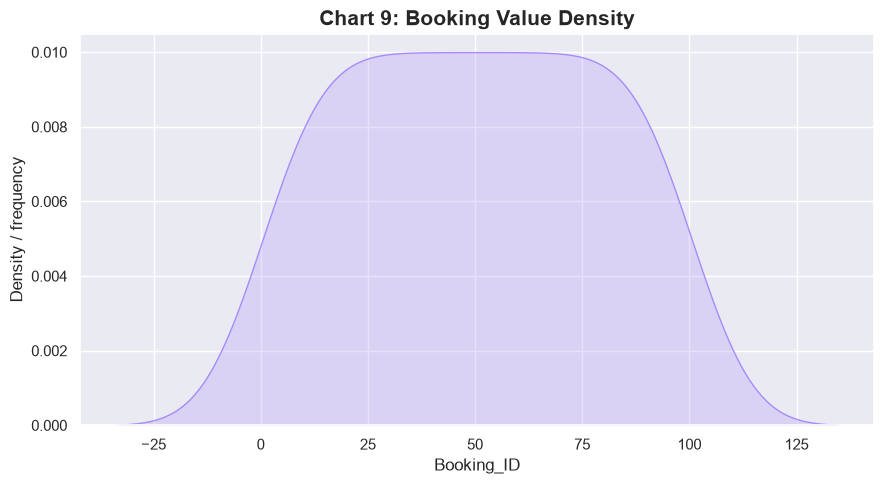

In [15]:
# Chart 9 — KDE plot (safe fallback for very small/constant datasets)
values = chart_df["_chart_value"].dropna()
plt.figure(figsize=(9, 5))
if len(values) >= 2 and values.nunique() > 1:
    sns.kdeplot(x=values, fill=True, color="#a78bfa", warn_singular=False)
else:
    sns.histplot(values, bins=max(1, min(5, len(values))), color="#a78bfa")
plt.title("Chart 9: Booking Value Density", fontsize=15, weight="bold")
plt.xlabel(value_col or "Record value")
plt.ylabel("Density / frequency")
plt.tight_layout()
plt.show()


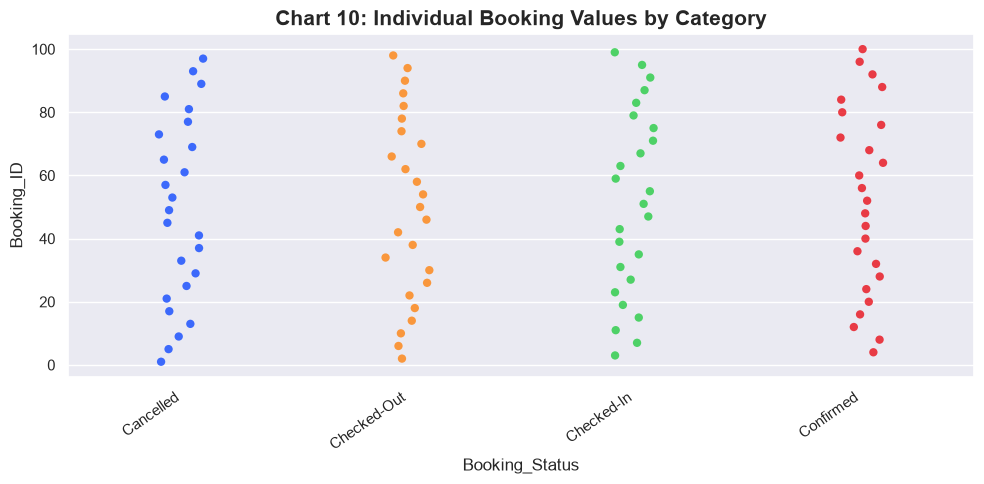

In [16]:
# Chart 10 — Strip plot
plt.figure(figsize=(10, 5))
sns.stripplot(data=chart_df, x="_chart_category", y="_chart_value", hue="_chart_category", legend=False, jitter=True, alpha=0.75, size=6, palette="bright")
plt.title("Chart 10: Individual Booking Values by Category", fontsize=15, weight="bold")
plt.xlabel(category_col or "Category")
plt.ylabel(value_col or "Record value")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


# Part B — Dashboard 1: Booking Trends
**Four chart types:** Area chart, heatmap, bubble chart, and multi-line chart. These are separate from the 10 individual chart types above.

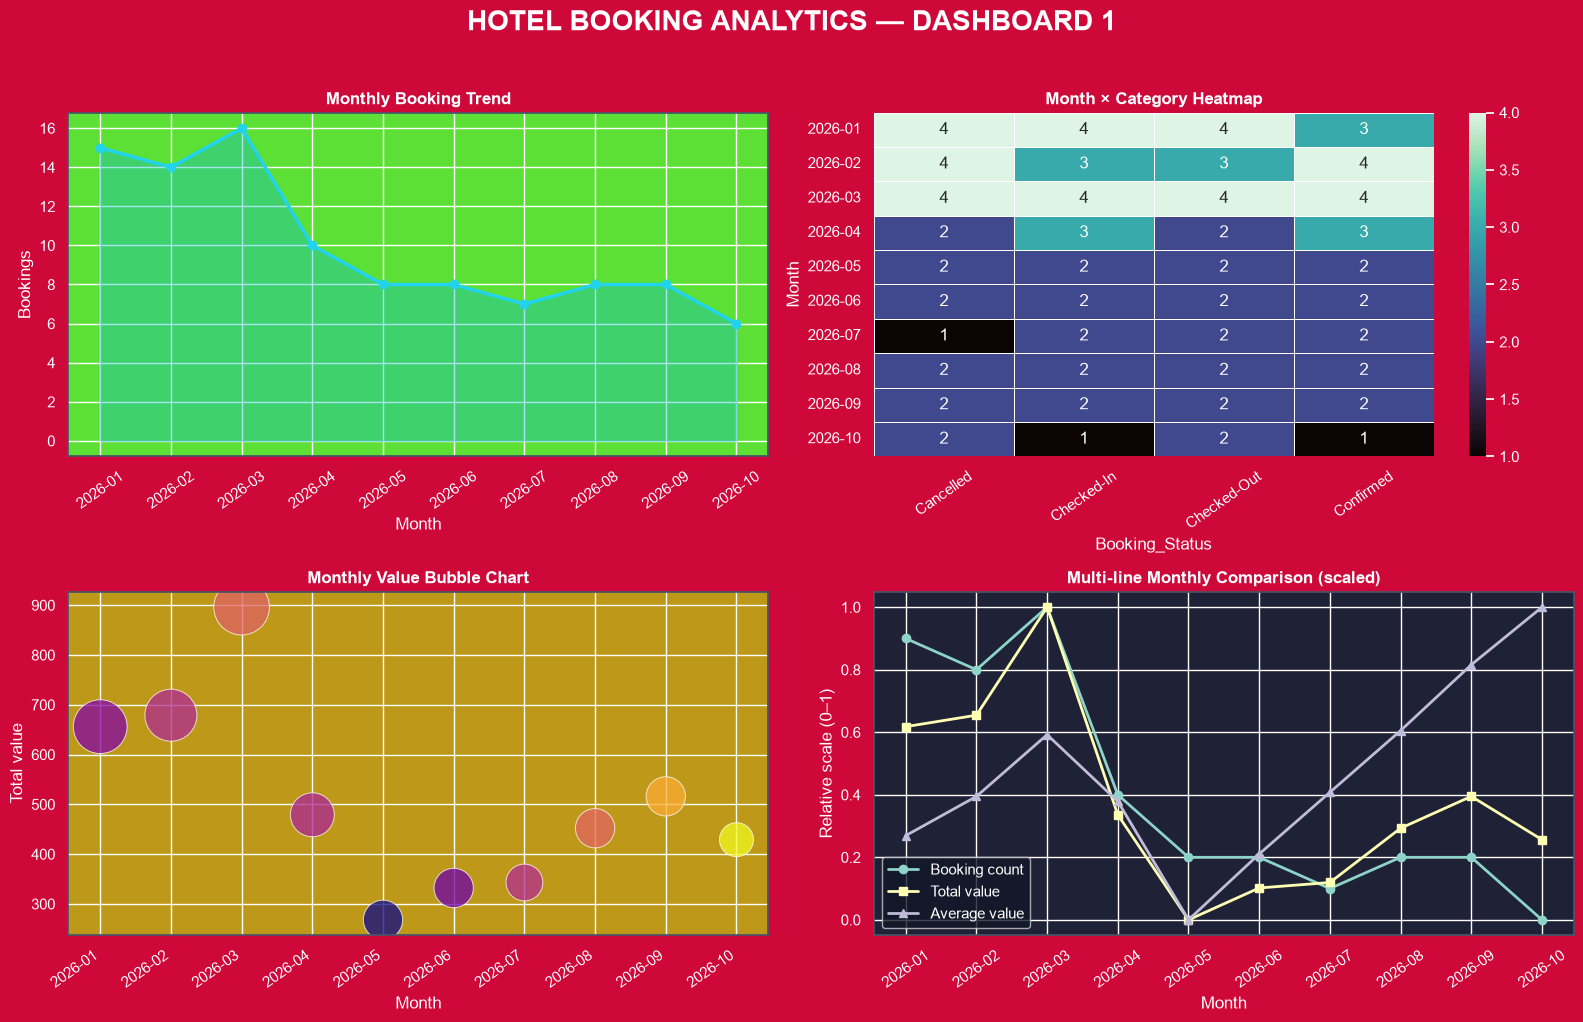

In [17]:
# Prepare monthly summaries for Dashboard 1
dash1 = chart_df.copy()
dash1["_month"] = dash1["_chart_date"].dt.to_period("M").astype(str)
monthly = dash1.groupby("_month").agg(
    booking_count=("_chart_value", "size"),
    total_value=("_chart_value", "sum"),
    average_value=("_chart_value", "mean")
).reset_index()

# Keep dashboard attractive and readable in dark theme
plt.style.use("dark_background")
fig, axes = plt.subplots(2, 2, figsize=(16, 10), facecolor="#CF083A")
fig.suptitle("HOTEL BOOKING ANALYTICS — DASHBOARD 1", fontsize=20, fontweight="bold", color="white", y=1.02)

# 1. Area chart
ax = axes[0, 0]
ax.set_facecolor("#5de035")
ax.fill_between(monthly["_month"], monthly["booking_count"], color="#06b6d4", alpha=0.35)
ax.plot(monthly["_month"], monthly["booking_count"], color="#22d3ee", linewidth=2.5, marker="o")
ax.set_title("Monthly Booking Trend", color="white", fontweight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Bookings")
ax.tick_params(axis="x", rotation=35, colors="white")
ax.tick_params(axis="y", colors="white")

# 2. Heatmap: month-by-category booking counts
heat = pd.crosstab(dash1["_month"], dash1["_chart_category"]).tail(12)
ax = axes[0, 1]
ax.set_facecolor("#1f2937")
sns.heatmap(heat, cmap="mako", annot=True, fmt="g", linewidths=.4, ax=ax, cbar=True)
ax.set_title("Month × Category Heatmap", color="white", fontweight="bold")
ax.set_xlabel(category_col or "Category")
ax.set_ylabel("Month")
ax.tick_params(axis="x", rotation=35, colors="white")
ax.tick_params(axis="y", colors="white")

# 3. Bubble chart: month, value, bubble size = booking count
bubble = monthly.copy()
bubble["_x"] = np.arange(len(bubble))
ax = axes[1, 0]
ax.set_facecolor("#BE9818")
sizes = np.maximum(bubble["booking_count"].to_numpy(dtype=float), 1) * 100
ax.scatter(bubble["_x"], bubble["total_value"], s=sizes, c=bubble["average_value"], cmap="plasma", alpha=.75, edgecolors="white", linewidths=.7)
ax.set_title("Monthly Value Bubble Chart", color="white", fontweight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Total value")
ax.set_xticks(bubble["_x"])
ax.set_xticklabels(bubble["_month"], rotation=35, ha="right", color="white")
ax.tick_params(axis="y", colors="white")

# 4. Multi-line chart: count, total and average scaled for comparison
ax = axes[1, 1]
ax.set_facecolor("#1f2137")
def scale_01(series):
    s = series.astype(float)
    span = s.max() - s.min()
    return (s - s.min()) / span if span else s * 0
ax.plot(monthly["_month"], scale_01(monthly["booking_count"]), marker="o", linewidth=2, label="Booking count")
ax.plot(monthly["_month"], scale_01(monthly["total_value"]), marker="s", linewidth=2, label="Total value")
ax.plot(monthly["_month"], scale_01(monthly["average_value"]), marker="^", linewidth=2, label="Average value")
ax.set_title("Multi-line Monthly Comparison (scaled)", color="white", fontweight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Relative scale (0–1)")
ax.tick_params(axis="x", rotation=35, colors="white")
ax.tick_params(axis="y", colors="white")
ax.legend(facecolor="#111827", labelcolor="white")

for ax in axes.flat:
    for spine in ax.spines.values():
        spine.set_color("#475569")
fig.tight_layout()
plt.show()
plt.style.use("default")


# Part C — Dashboard 2: Revenue & Guest Insights
**Four chart types:** stacked bar chart, joint-style relationship plot with marginal distributions, polar chart, and category-versus-value scatter chart.

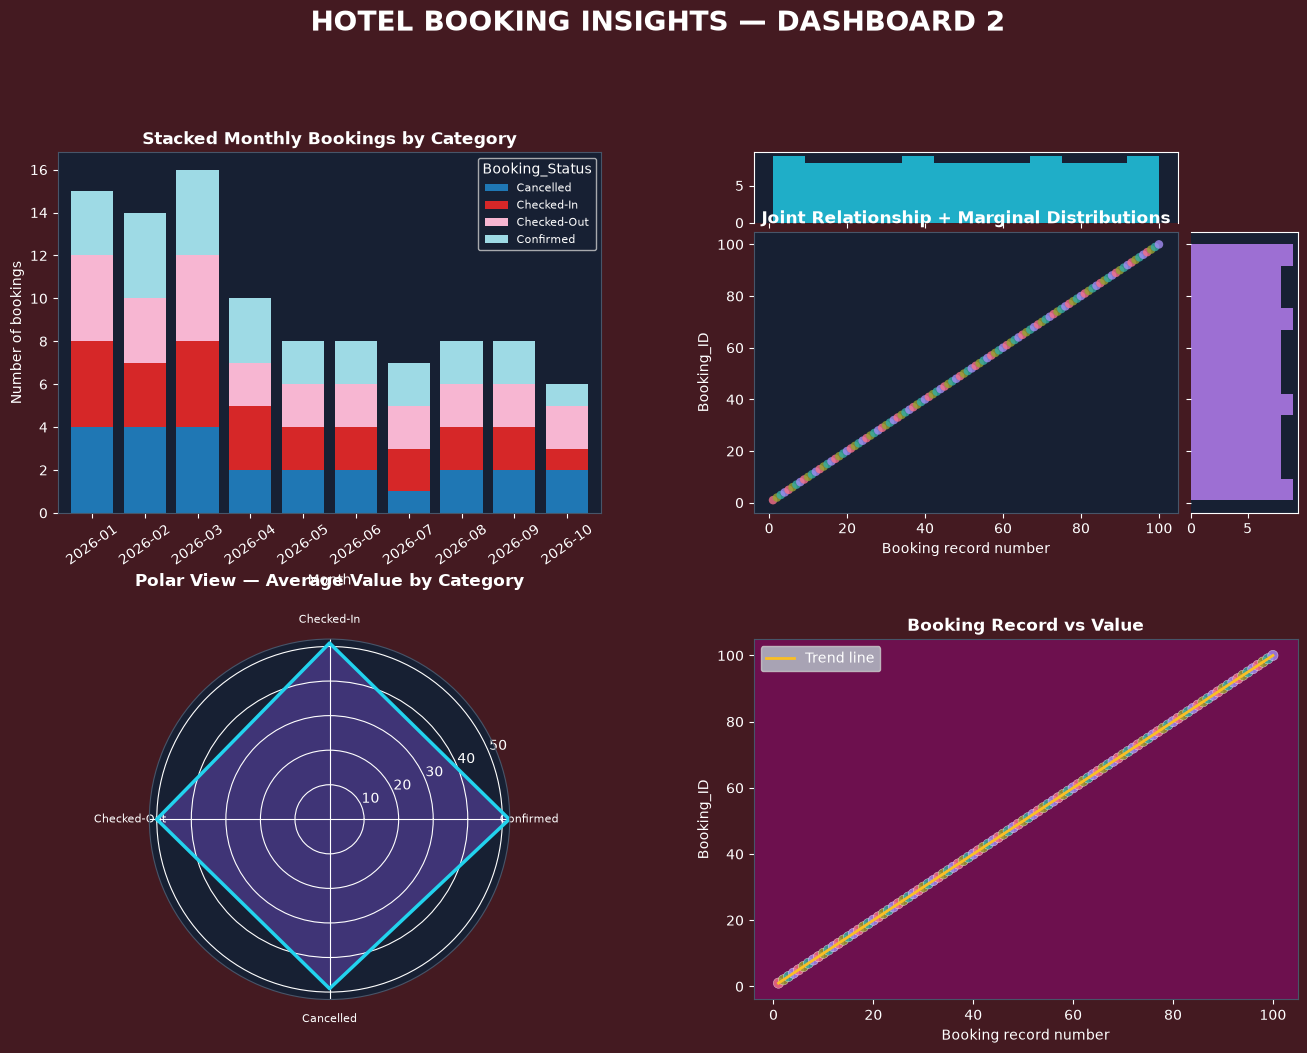

In [18]:
# Prepare data for Dashboard 2
dash2 = chart_df.copy()
dash2["_month"] = dash2["_chart_date"].dt.to_period("M").astype(str)
stack_data = pd.crosstab(dash2["_month"], dash2["_chart_category"]).tail(10)

# A separate 2x2 dashboard with dark styling
plt.style.use("dark_background")
fig = plt.figure(figsize=(16, 11), facecolor="#441A21")
fig.suptitle("HOTEL BOOKING INSIGHTS — DASHBOARD 2", fontsize=20, fontweight="bold", color="white", y=1.01)
gs = fig.add_gridspec(2, 2, hspace=0.35, wspace=0.28)

# 1. Stacked bar chart
ax1 = fig.add_subplot(gs[0, 0])
ax1.set_facecolor("#172033")
if not stack_data.empty:
    stack_data.plot(kind="bar", stacked=True, ax=ax1, colormap="tab20", width=0.8)
ax1.set_title("Stacked Monthly Bookings by Category", color="white", fontweight="bold")
ax1.set_xlabel("Month")
ax1.set_ylabel("Number of bookings")
ax1.tick_params(axis="x", rotation=35, colors="white")
ax1.tick_params(axis="y", colors="white")
ax1.legend(title=category_col or "Category", fontsize=8, facecolor="#172033", labelcolor="white")

# 2. Joint-style plot: scatter with marginal histograms in a nested layout
subgs = gs[0, 1].subgridspec(2, 2, height_ratios=[1, 4], width_ratios=[4, 1], hspace=0.05, wspace=0.05)
ax_top = fig.add_subplot(subgs[0, 0])
ax_joint = fig.add_subplot(subgs[1, 0])
ax_right = fig.add_subplot(subgs[1, 1])
x_vals = np.arange(1, len(dash2) + 1)
y_vals = dash2["_chart_value"].to_numpy(dtype=float)
cats = dash2["_chart_category"]
palette = sns.color_palette("husl", n_colors=max(1, cats.nunique()))
cat_map = {cat: palette[i] for i, cat in enumerate(cats.unique())}
point_colors = cats.map(cat_map)
ax_joint.scatter(x_vals, y_vals, c=list(point_colors), alpha=.8, s=38, edgecolors="none")
ax_top.hist(x_vals, bins=min(12, max(1, len(x_vals))), color="#22d3ee", alpha=.8)
ax_right.hist(y_vals, bins=12, orientation="horizontal", color="#c084fc", alpha=.8)
ax_joint.set_title("Joint Relationship + Marginal Distributions", color="white", fontweight="bold")
ax_joint.set_xlabel("Booking record number")
ax_joint.set_ylabel(value_col or "Record value")
ax_top.tick_params(labelbottom=False, colors="white")
ax_right.tick_params(labelleft=False, colors="white")
for a in [ax_top, ax_joint, ax_right]:
    a.set_facecolor("#172033")
    a.tick_params(colors="white")
ax_top.spines["bottom"].set_visible(False)
ax_right.spines["left"].set_visible(False)

# 3. Polar chart: average value by category
ax3 = fig.add_subplot(gs[1, 0], projection="polar")
ax3.set_facecolor("#172033")
polar_data = dash2.groupby("_chart_category")["_chart_value"].mean().sort_values(ascending=False).head(8)
if len(polar_data) > 0:
    vals = polar_data.to_numpy(dtype=float)
    labels = polar_data.index.astype(str).tolist()
    angles = np.linspace(0, 2 * np.pi, len(vals), endpoint=False)
    vals_closed = np.r_[vals, vals[0]]
    angles_closed = np.r_[angles, angles[0]]
    ax3.plot(angles_closed, vals_closed, color="#22d3ee", linewidth=2.5)
    ax3.fill(angles_closed, vals_closed, color="#8b5cf6", alpha=.35)
    ax3.set_xticks(angles)
    ax3.set_xticklabels(labels, color="white", fontsize=8)
ax3.set_title("Polar View — Average Value by Category", color="white", fontweight="bold", pad=20)
ax3.tick_params(colors="white")

# 4. Scatter chart with trend line (no sns.regplot)
ax4 = fig.add_subplot(gs[1, 1])
ax4.set_facecolor("#6D104E")
ax4.scatter(x_vals, y_vals, c=list(point_colors), alpha=.8, s=55, edgecolors="white", linewidths=.3)
if len(x_vals) >= 2 and np.unique(x_vals).size > 1 and np.isfinite(y_vals).sum() >= 2:
    good = np.isfinite(y_vals)
    if good.sum() >= 2:
        m, b = np.polyfit(x_vals[good], y_vals[good], 1)
        ax4.plot(x_vals, m * x_vals + b, color="#fbbf24", linewidth=2, label="Trend line")
        ax4.legend(facecolor="#B8C9CF", labelcolor="white")
ax4.set_title("Booking Record vs Value", color="white", fontweight="bold")
ax4.set_xlabel("Booking record number")
ax4.set_ylabel(value_col or "Record value")
ax4.tick_params(colors="white")

for ax in [ax1, ax_joint, ax3, ax4]:
    for spine in ax.spines.values():
        spine.set_color("#475569")
fig.tight_layout()
plt.show()
plt.style.use("default")


## 5. Optional: preview all tables
Use this to confirm the records loaded from MySQL.

In [17]:
display(guests_df.head(10))
display(rooms_df.head(10))
display(bookings_df.head(10))


,Guest_ID,Guest_Name,City,Phone,Email
0,1,Aarav Sharma,Erode,9000007919,guest001@example.com
1,2,Diya Rajan,Vellore,9000015838,guest002@example.com
2,3,Arjun Devi,Hosur,9000023757,guest003@example.com
3,4,Ananya Patel,Coimbatore,9000031676,guest004@example.com
4,5,Ravi Singh,Salem,9000039595,guest005@example.com
5,6,Priya Das,Trichy,9000047514,guest006@example.com
6,7,Kavin Iyer,Coimbatore,9000055433,guest007@example.com
7,8,Meena Reddy,Salem,9000063352,guest008@example.com
8,9,Vijay Nair,Trichy,9000071271,guest009@example.com
9,10,Nila Kumar,Bengaluru,9000079190,guest010@example.com


,Room_ID,Room_Type,Price_Per_Night,Room_Status
0,1,Standard,1500.0,Maintenance
1,2,Deluxe,2500.0,Occupied
2,3,Suite,4500.0,Available
3,4,Family,3500.0,Maintenance
4,5,Standard,1525.0,Occupied
5,6,Deluxe,2525.0,Available
6,7,Suite,4525.0,Maintenance
7,8,Family,3525.0,Occupied
8,9,Standard,1550.0,Available
9,10,Deluxe,2550.0,Maintenance


,Booking_ID,Guest_ID,Room_ID,Check_In,Check_Out,Booking_Status
0,1,7,13,2026-01-05,2026-01-07,Cancelled
1,2,14,26,2026-01-09,2026-01-12,Checked-Out
2,3,21,39,2026-01-13,2026-01-17,Checked-In
3,4,28,52,2026-01-17,2026-01-22,Confirmed
4,5,35,65,2026-01-21,2026-01-22,Cancelled
5,6,42,78,2026-01-25,2026-01-27,Checked-Out
6,7,49,91,2026-01-29,2026-02-01,Checked-In
7,8,56,4,2026-02-02,2026-02-06,Confirmed
8,9,63,17,2026-02-06,2026-02-11,Cancelled
9,10,70,30,2026-02-10,2026-02-11,Checked-Out


## 6. Close the database connection
Run this only after you have finished generating charts.

In [ ]:
cursor.close()
connection.close()
print("MySQL connection closed.")
